In [1]:
# # India VIX EDA

# ## FINAURA — AI-Based Financial Market Regime Detection, Risk Forecasting & Portfolio Analytics

# This notebook performs Exploratory Data Analysis on the processed India VIX dataset.

# ### Objectives
# - Understand the structure and quality of the India VIX dataset
# - Analyze the historical VIX trend
# - Study VIX returns and volatility
# - Identify high and low volatility periods
# - Analyze the distribution of VIX values
# - Examine relationships between VIX features
# - Analyze the future 5-day volatility target
# - Identify important feature-target relationships

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
input_path = Path("../data/processed/india_vix_processed.csv")

print("Input file:")
print(input_path)

Input file:
..\data\processed\india_vix_processed.csv


In [4]:
df = pd.read_csv(input_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (2319, 24)


In [5]:
df.head()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,vix_change,vix_change_pct,target_5d_volatility
0,2017-03-15,12.42,12.42,12.53,11.20,12.40,0,0.001613,0.001612,0.001613,0.107085,13.450,13.506,13.5970,14.3476,0.911010,0.665513,0.519895,-0.105187,-0.092768,-0.262032,0.020000,0.161294,0.415843
1,2017-03-16,11.91,11.91,12.42,11.34,12.42,0,-0.041063,-0.041930,-0.041063,0.090680,13.016,13.339,13.5025,14.2692,0.854666,0.684094,0.533534,-0.154119,-0.136957,-0.292335,-0.510000,-4.106282,0.379160
2,2017-03-17,11.85,11.85,12.11,10.39,11.91,0,-0.005038,-0.005050,-0.005038,0.145148,12.508,13.188,13.3845,14.1870,0.761545,0.684955,0.515888,-0.176511,-0.166080,-0.295900,-0.059999,-0.503774,0.387038
3,2017-03-20,12.02,12.02,12.31,11.44,11.85,0,0.014346,0.014244,0.014346,0.072379,12.120,13.055,13.2990,14.1096,0.853164,0.695894,0.513139,-0.138968,-0.124545,-0.285799,0.170000,1.434600,0.461619
4,2017-03-21,11.94,11.94,12.16,11.03,12.02,0,-0.006656,-0.006678,-0.006656,0.094640,12.028,12.885,13.2245,14.0474,0.331839,0.673655,0.509894,-0.037097,-0.110946,-0.290553,-0.080001,-0.665565,0.514888


In [6]:
df.tail()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,vix_change,vix_change_pct,target_5d_volatility
2314,2026-08-25,11.08,11.08,11.62,9.45,11.53,0,-0.039029,-0.039811,-0.039029,0.195848,11.178,11.303,11.6785,12.5042,0.639636,0.444702,0.398492,-0.027217,-0.117834,-0.867480,-0.450000,-3.902861,0.721152
2315,2026-08-26,10.57,10.57,11.08,10.13,11.08,0,-0.046029,-0.047122,-0.046029,0.089877,11.028,11.191,11.6065,12.4484,0.704991,0.488522,0.401572,-0.066254,-0.119900,-0.873580,-0.510000,-4.602890,0.542775
2316,2026-08-27,11.07,11.07,11.28,10.36,10.57,0,0.047304,0.046219,0.047304,0.083108,11.090,11.156,11.5520,12.4060,0.720049,0.555758,0.438769,0.028810,-0.089638,-0.867600,0.500000,4.730369,0.558293
2317,2026-08-28,10.68,10.68,11.14,10.53,11.07,0,-0.035230,-0.035866,-0.035230,0.057116,10.986,11.093,11.4980,12.3662,0.692824,0.579462,0.440949,-0.046429,-0.091837,-0.872264,-0.389999,-3.523030,0.301674
2318,2026-08-31,11.19,11.19,11.44,10.68,10.68,0,0.047753,0.046648,0.047753,0.067918,10.918,11.079,11.4610,12.3306,0.762337,0.636696,0.473285,-0.029488,-0.062029,-0.866164,0.509999,4.775274,0.199703


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2319 entries, 0 to 2318
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  2319 non-null   object 
 1   adj_close             2319 non-null   float64
 2   close                 2319 non-null   float64
 3   high                  2319 non-null   float64
 4   low                   2319 non-null   float64
 5   open                  2319 non-null   float64
 6   volume                2319 non-null   int64  
 7   daily_return          2319 non-null   float64
 8   log_return            2319 non-null   float64
 9   intraday_return       2319 non-null   float64
 10  price_range           2319 non-null   float64
 11  ma_5                  2319 non-null   float64
 12  ma_10                 2319 non-null   float64
 13  ma_20                 2319 non-null   float64
 14  ma_50                 2319 non-null   float64
 15  volatility_5d        

In [8]:
rows, columns = df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 2319
Number of columns: 24


In [9]:
print("Available columns:")

for col in df.columns:
    print(col)

Available columns:
date
adj_close
close
high
low
open
volume
daily_return
log_return
intraday_return
price_range
ma_5
ma_10
ma_20
ma_50
volatility_5d
volatility_10d
volatility_20d
momentum_5d
momentum_20d
drawdown
vix_change
vix_change_pct
target_5d_volatility


In [10]:
print(df.dtypes)

date                     object
adj_close               float64
close                   float64
high                    float64
low                     float64
open                    float64
volume                    int64
daily_return            float64
log_return              float64
intraday_return         float64
price_range             float64
ma_5                    float64
ma_10                   float64
ma_20                   float64
ma_50                   float64
volatility_5d           float64
volatility_10d          float64
volatility_20d          float64
momentum_5d             float64
momentum_20d            float64
drawdown                float64
vix_change              float64
vix_change_pct          float64
target_5d_volatility    float64
dtype: object


In [11]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date conversion completed.")
print(df["date"].dtype)

Date conversion completed.
datetime64[ns]


In [12]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Start date: 2017-03-15 00:00:00
End date: 2026-08-31 00:00:00


In [13]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
date                    0
adj_close               0
close                   0
high                    0
low                     0
open                    0
volume                  0
daily_return            0
log_return              0
intraday_return         0
price_range             0
ma_5                    0
ma_10                   0
ma_20                   0
ma_50                   0
volatility_5d           0
volatility_10d          0
volatility_20d          0
momentum_5d             0
momentum_20d            0
drawdown                0
vix_change              0
vix_change_pct          0
target_5d_volatility    0
dtype: int64


In [14]:
duplicate_rows = df.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


In [15]:
df.describe()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,vix_change,vix_change_pct,target_5d_volatility
count,2319,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.0,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000,2319.000000
mean,2021-12-05 20:49:59.223803392,16.509888,16.509888,17.230966,15.145606,16.508762,0.0,0.001375,-0.000044,0.001452,0.124406,16.512029,16.514967,16.519872,16.531929,0.717418,0.751007,0.774146,0.005993,0.028486,-0.636693,-0.000522,0.137497,0.716819
min,2017-03-15 00:00:00,9.150000,9.150000,9.400000,8.180000,9.150000,0.0,-0.297503,-0.353114,-0.297503,0.024675,9.384000,9.496000,9.856000,10.993000,0.032480,0.215886,0.303825,-0.447850,-0.545030,-0.890563,-8.219999,-29.750270,0.032480
25%,2019-07-20 12:00:00,12.655000,12.655000,13.160000,11.575000,12.655000,0.0,-0.027601,-0.027989,-0.027594,0.075525,12.690000,12.811500,12.880500,13.191400,0.436403,0.509983,0.553907,-0.061587,-0.115414,-0.835785,-0.425000,-2.760127,0.435949
50%,2021-12-13 00:00:00,14.780000,14.780000,15.490000,13.560000,14.780000,0.0,-0.003331,-0.003336,-0.003181,0.110060,14.820000,14.870000,14.894000,14.907800,0.609275,0.658299,0.693443,-0.004513,-0.016393,-0.765937,-0.050000,-0.333055,0.608355
75%,2024-04-23 12:00:00,18.464999,18.464999,19.420000,16.985000,18.464999,0.0,0.023744,0.023466,0.024102,0.155140,18.610000,18.605500,18.552000,18.441900,0.848477,0.851848,0.885872,0.060758,0.096645,-0.399600,0.365000,2.374374,0.847737
max,2026-08-31 00:00:00,83.610001,83.610001,86.639999,75.970001,83.610001,0.0,0.656250,0.504556,0.656250,0.506091,75.029999,71.470999,62.916500,48.264800,4.463848,3.022378,2.126252,1.296412,4.254744,0.000000,11.620003,65.625004,4.463848
std,NaN,6.611646,6.611646,6.980770,6.167913,6.610278,0.0,0.054476,0.052841,0.054372,0.067225,6.530669,6.424517,6.177929,5.554345,0.456236,0.386922,0.329452,0.120505,0.327533,0.255077,1.124853,5.447593,0.456364


In [16]:
print("Columns containing 'close':")

close_columns = [
    col for col in df.columns
    if "close" in col.lower()
]

print(close_columns)

Columns containing 'close':
['adj_close', 'close']


In [17]:
if "close" in df.columns:
    vix_column = "close"
elif "vix_close" in df.columns:
    vix_column = "vix_close"
else:
    vix_column = close_columns[0]

print("Selected VIX column:", vix_column)

Selected VIX column: close


In [18]:
vix_stats = df[vix_column].describe()

vix_stats

count    2319.000000
mean       16.509888
std         6.611646
min         9.150000
25%        12.655000
50%        14.780000
75%        18.464999
max        83.610001
Name: close, dtype: float64

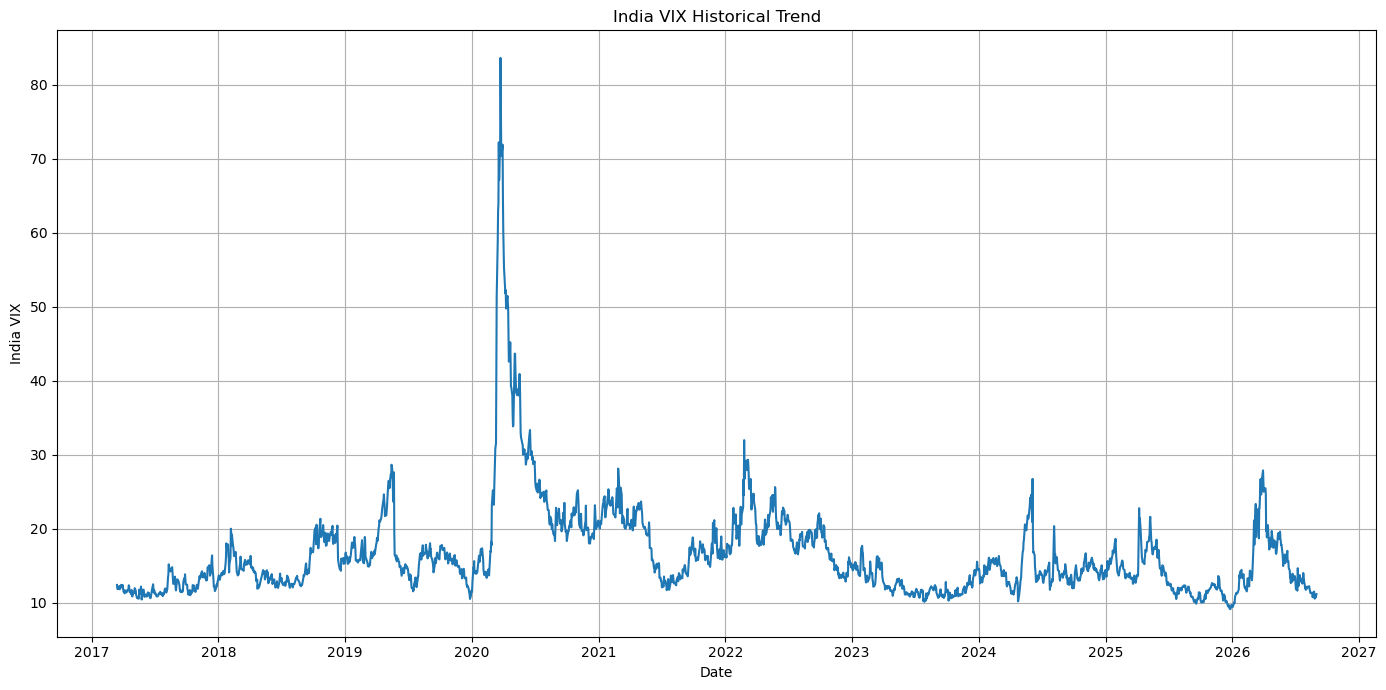

In [19]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[vix_column]
)

plt.title("India VIX Historical Trend")
plt.xlabel("Date")
plt.ylabel("India VIX")
plt.grid(True)
plt.tight_layout()
plt.show()

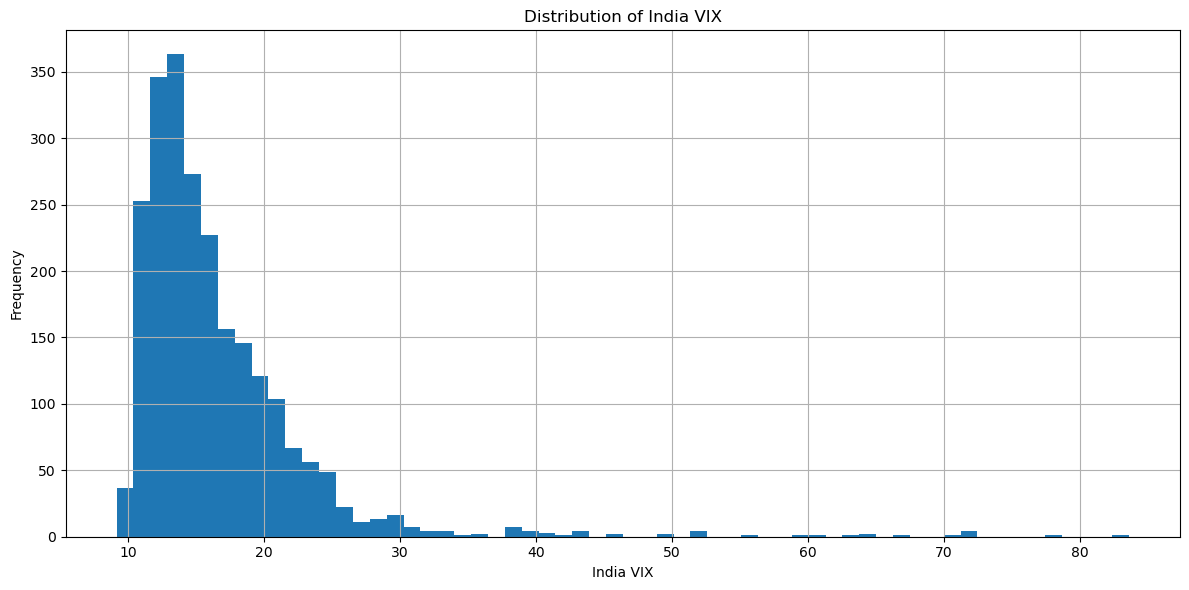

In [20]:
plt.figure(figsize=(12, 6))

plt.hist(
    df[vix_column].dropna(),
    bins=60
)

plt.title("Distribution of India VIX")
plt.xlabel("India VIX")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

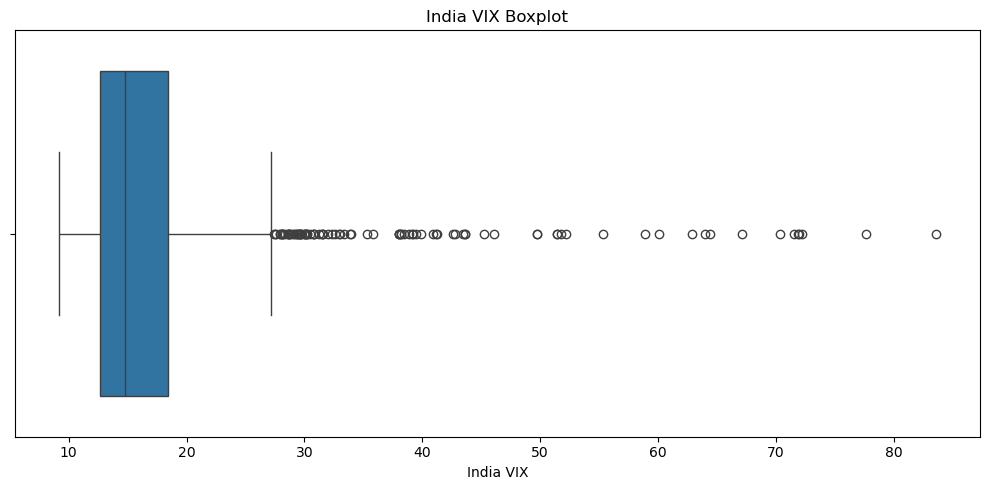

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df[vix_column].dropna()
)

plt.title("India VIX Boxplot")
plt.xlabel("India VIX")
plt.tight_layout()
plt.show()

In [22]:
return_columns = [
    col for col in df.columns
    if "return" in col.lower()
]

print("Return columns:")
print(return_columns)

Return columns:
['daily_return', 'log_return', 'intraday_return']


In [23]:
if "daily_return" in df.columns:

    print(df["daily_return"].describe())
    
elif "return" in df.columns:

    print(df["return"].describe())
    
else:

    print("Daily return column not found.")

count    2319.000000
mean        0.001375
std         0.054476
min        -0.297503
25%        -0.027601
50%        -0.003331
75%         0.023744
max         0.656250
Name: daily_return, dtype: float64


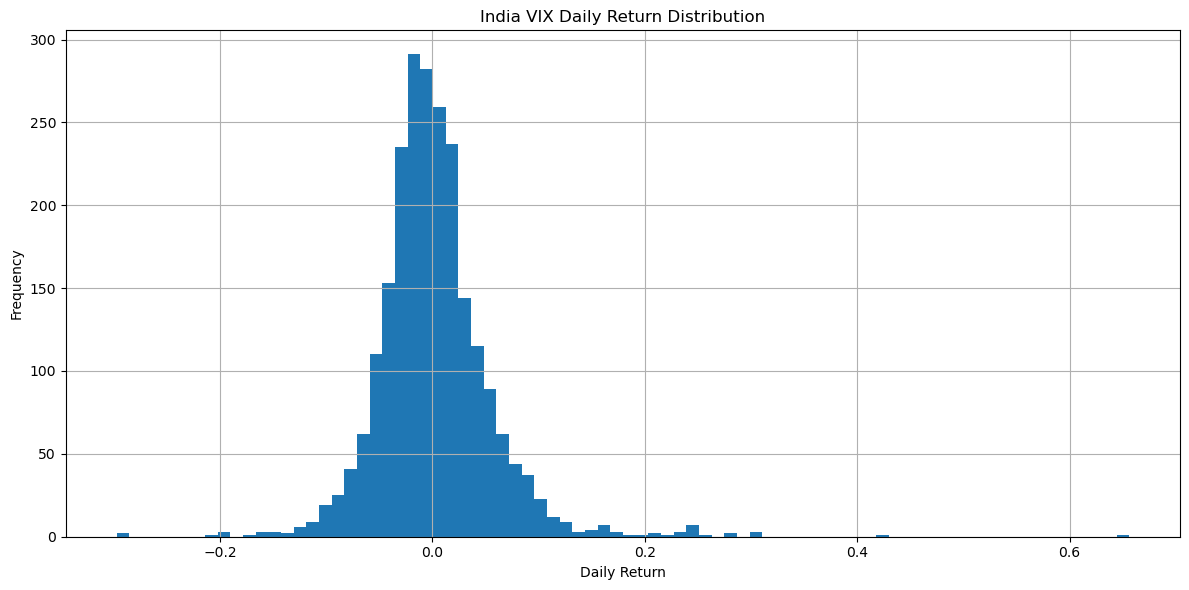

In [24]:
if "daily_return" in df.columns:

    plt.figure(figsize=(12, 6))

    plt.hist(
        df["daily_return"].dropna(),
        bins=80
    )

    plt.title("India VIX Daily Return Distribution")
    plt.xlabel("Daily Return")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

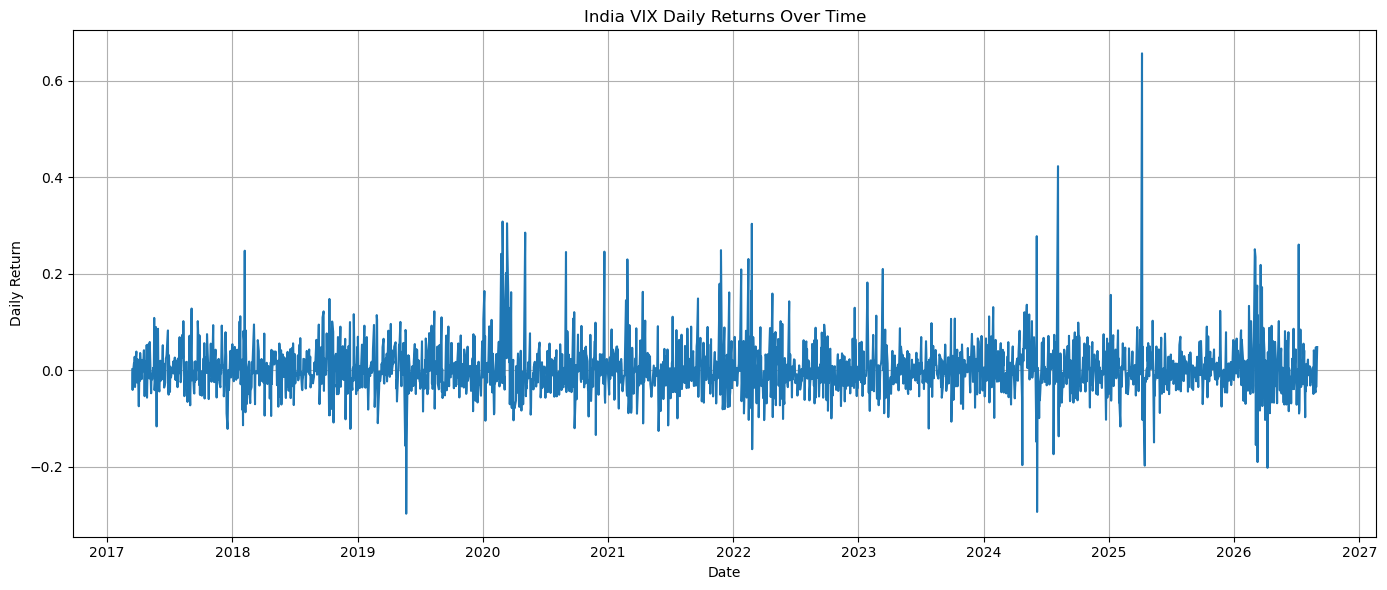

In [25]:
if "daily_return" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["date"],
        df["daily_return"]
    )

    plt.title("India VIX Daily Returns Over Time")
    plt.xlabel("Date")
    plt.ylabel("Daily Return")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [26]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility columns:")
print(volatility_columns)

Volatility columns:
['volatility_5d', 'volatility_10d', 'volatility_20d', 'target_5d_volatility']


In [27]:
if "volatility_20d" in df.columns:
    volatility_col = "volatility_20d"

elif "volatility_20" in df.columns:
    volatility_col = "volatility_20"

else:
    volatility_col = volatility_columns[-1]

print("Selected volatility column:", volatility_col)

Selected volatility column: volatility_20d


In [28]:
volatility_stats = df[volatility_col].describe()

volatility_stats

count    2319.000000
mean        0.774146
std         0.329452
min         0.303825
25%         0.553907
50%         0.693443
75%         0.885872
max         2.126252
Name: volatility_20d, dtype: float64

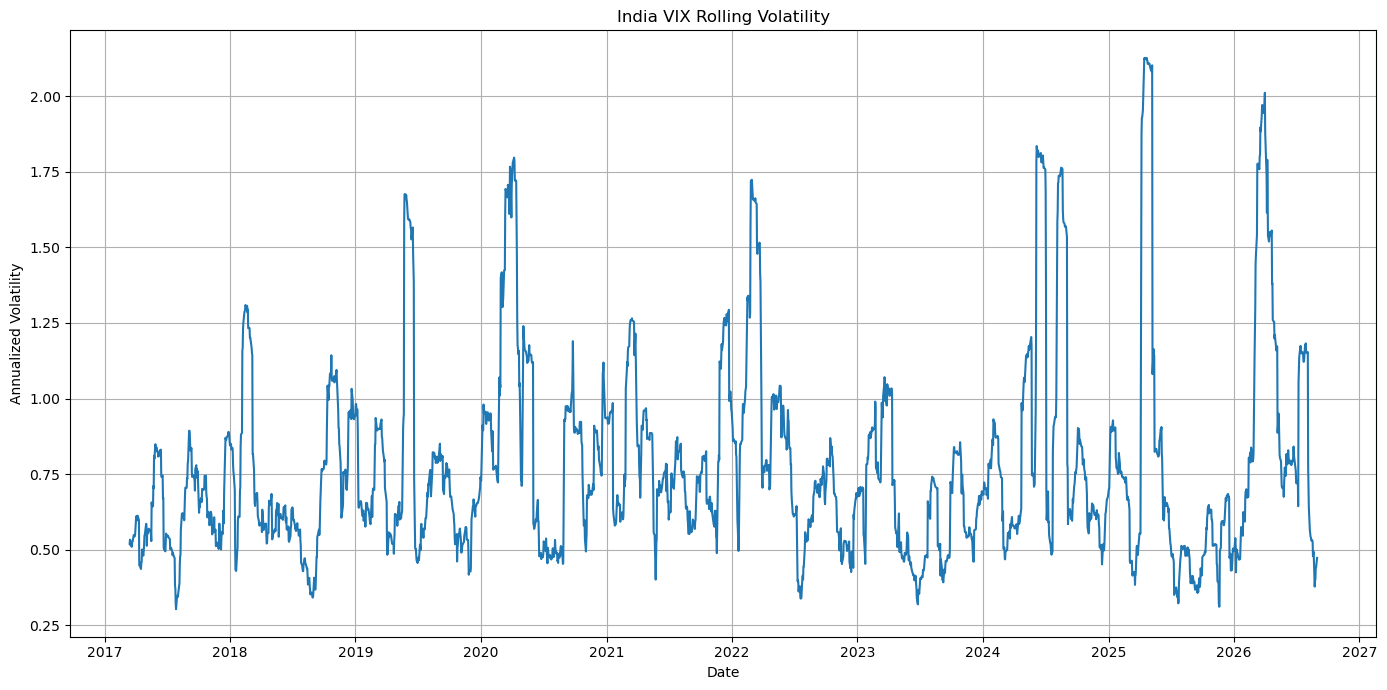

In [29]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[volatility_col]
)

plt.title("India VIX Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
highest_vix = (
    df[
        ["date", vix_column]
    ]
    .dropna()
    .sort_values(
        vix_column,
        ascending=False
    )
    .head(20)
)

highest_vix

,date,close
743,2020-03-24,83.610001
744,2020-03-25,77.629997
740,2020-03-19,72.199997
742,2020-03-23,71.989998
747,2020-03-30,71.889999
745,2020-03-26,71.529999
746,2020-03-27,70.389999
741,2020-03-20,67.099998
748,2020-03-31,64.410004
739,2020-03-18,63.959999


In [31]:
lowest_vix = (
    df[
        ["date", vix_column]
    ]
    .dropna()
    .sort_values(
        vix_column,
        ascending=True
    )
    .head(20)
)

lowest_vix

,date,close
2153,2025-12-26,9.15
2152,2025-12-24,9.19
2151,2025-12-23,9.38
2157,2026-01-02,9.45
2156,2025-12-31,9.48
2149,2025-12-19,9.52
2150,2025-12-22,9.68
2155,2025-12-30,9.68
2148,2025-12-18,9.71
2154,2025-12-29,9.72


In [32]:
high_vix_threshold = df[vix_column].quantile(0.90)

print(
    "90th percentile VIX threshold:",
    round(high_vix_threshold, 2)
)

90th percentile VIX threshold: 22.72


In [33]:
high_vix_days = df[
    df[vix_column] >= high_vix_threshold
].copy()

print("Number of high-VIX observations:", len(high_vix_days))

high_vix_days[
    ["date", vix_column]
].head(20)

Number of high-VIX observations: 232


,date,close
517,2019-04-18,22.740000
518,2019-04-22,24.049999
519,2019-04-23,24.650000
520,2019-04-24,23.709999
521,2019-04-25,23.230000
524,2019-05-02,22.980000
525,2019-05-03,24.030001
526,2019-05-06,26.430000
527,2019-05-07,26.480000
528,2019-05-08,26.370001


In [34]:
ma_columns = [
    col for col in df.columns
    if col.lower().startswith("ma_")
]

print("Moving average columns:")
print(ma_columns)

Moving average columns:
['ma_5', 'ma_10', 'ma_20', 'ma_50']


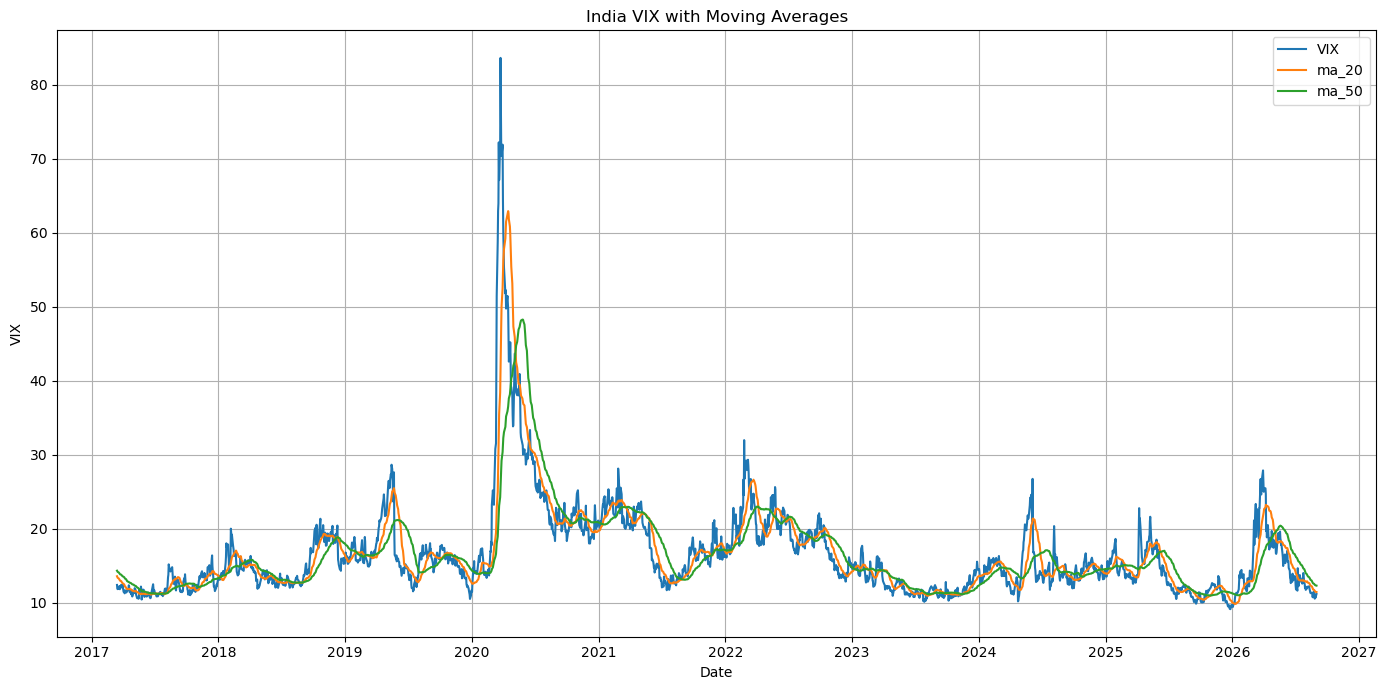

In [35]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[vix_column],
    label="VIX"
)

for ma in ["ma_20", "ma_50"]:
    if ma in df.columns:
        plt.plot(
            df["date"],
            df[ma],
            label=ma
        )

plt.title("India VIX with Moving Averages")
plt.xlabel("Date")
plt.ylabel("VIX")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum columns:")
print(momentum_columns)

Momentum columns:
['momentum_5d', 'momentum_20d']


In [37]:
if momentum_columns:
    df[momentum_columns].describe()
else:
    print("Momentum columns not found.")

In [38]:
if "momentum_20" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["date"],
        df["momentum_20"]
    )

    plt.title("India VIX 20-Day Momentum")
    plt.xlabel("Date")
    plt.ylabel("Momentum")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [39]:
target_column = "target_5d_volatility"

print("Target column:", target_column)

print("\nTarget statistics:")
print(df[target_column].describe())

Target column: target_5d_volatility

Target statistics:
count    2319.000000
mean        0.716819
std         0.456364
min         0.032480
25%         0.435949
50%         0.608355
75%         0.847737
max         4.463848
Name: target_5d_volatility, dtype: float64


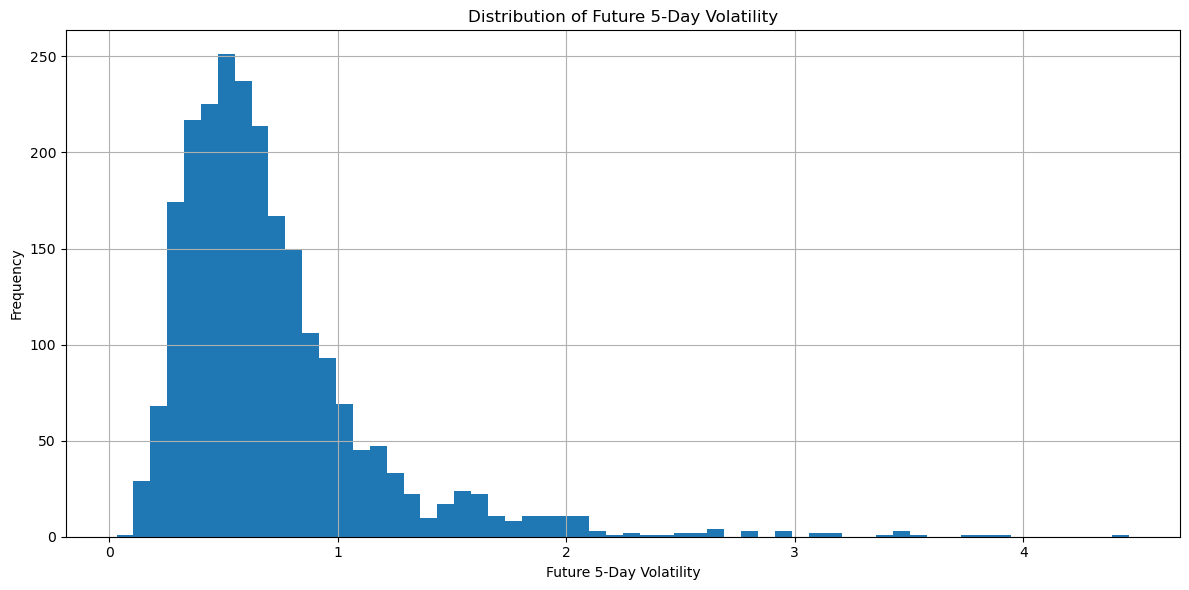

In [40]:
plt.figure(figsize=(12, 6))

plt.hist(
    df[target_column].dropna(),
    bins=60
)

plt.title("Distribution of Future 5-Day Volatility")
plt.xlabel("Future 5-Day Volatility")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

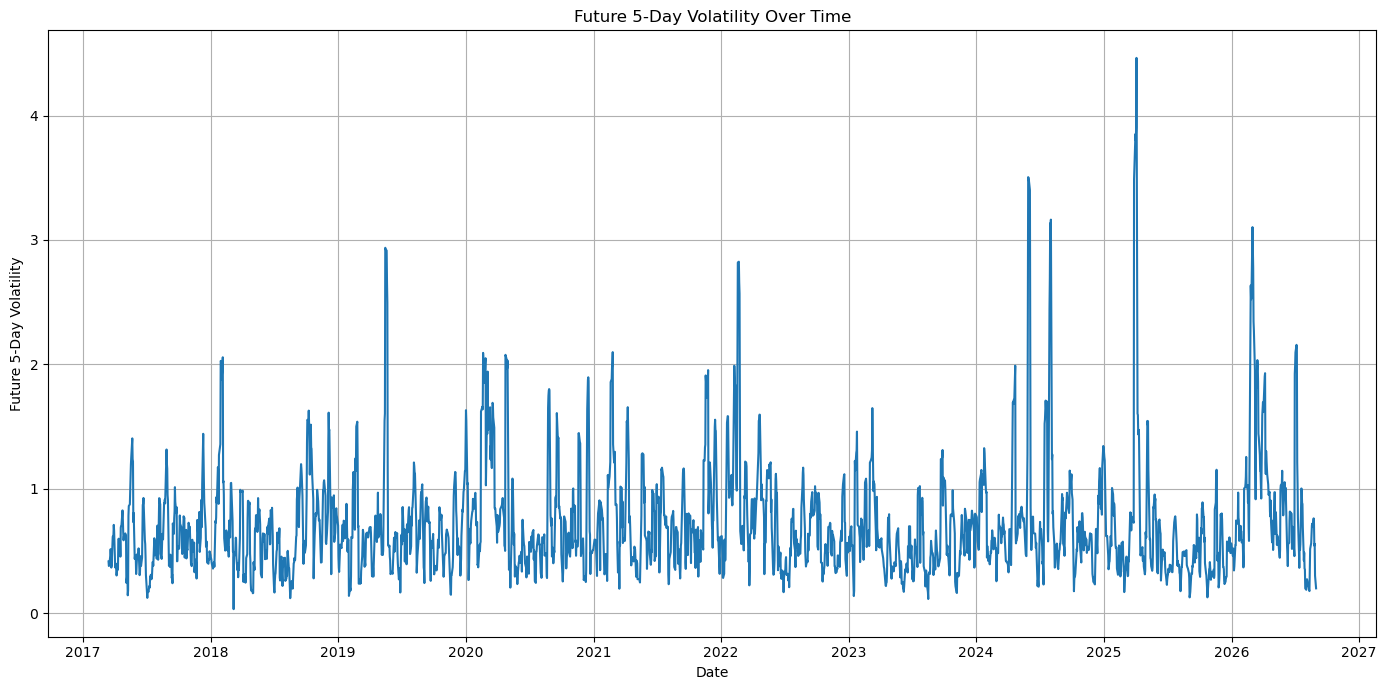

In [41]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[target_column]
)

plt.title("Future 5-Day Volatility Over Time")
plt.xlabel("Date")
plt.ylabel("Future 5-Day Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

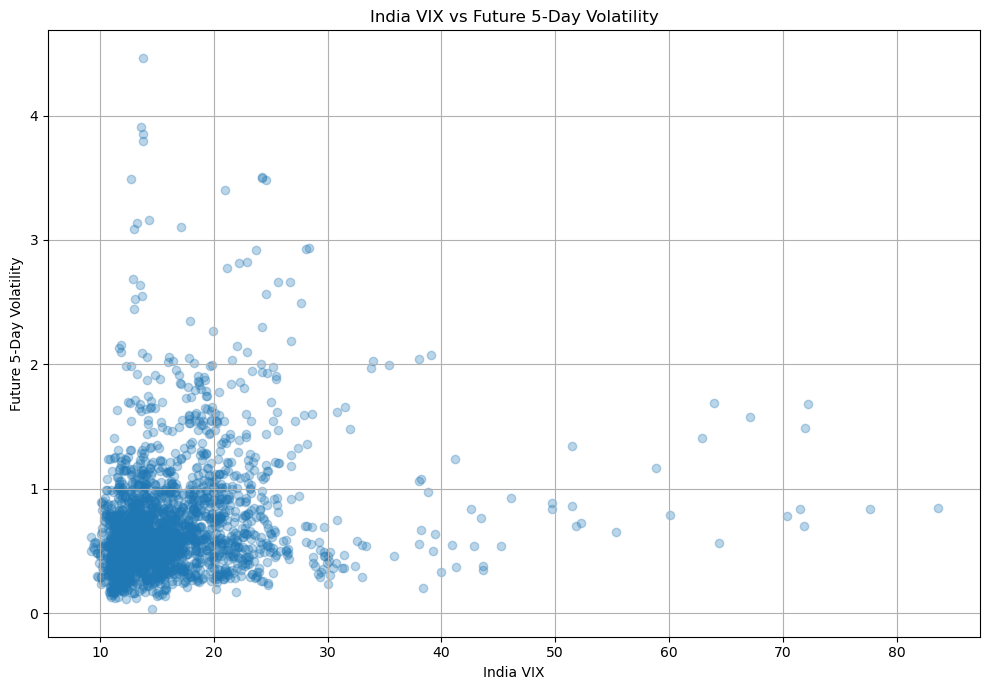

In [42]:
plt.figure(figsize=(10, 7))

plt.scatter(
    df[vix_column],
    df[target_column],
    alpha=0.3
)

plt.title("India VIX vs Future 5-Day Volatility")
plt.xlabel("India VIX")
plt.ylabel("Future 5-Day Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

In [43]:
numeric_df = df.select_dtypes(
    include=np.number
)

correlation_matrix = numeric_df.corr()

print(
    "Correlation matrix shape:",
    correlation_matrix.shape
)

Correlation matrix shape: (23, 23)


In [44]:
target_correlations = (
    correlation_matrix[target_column]
    .sort_values(ascending=False)
)

target_correlations

target_5d_volatility    1.000000
volatility_5d           0.224184
momentum_20d            0.210250
volatility_10d          0.207879
high                    0.198458
momentum_5d             0.195560
close                   0.192339
adj_close               0.192339
volatility_20d          0.185652
open                    0.177043
low                     0.166713
ma_5                    0.165657
price_range             0.153233
ma_10                   0.141690
ma_20                   0.115904
daily_return            0.108409
vix_change_pct          0.108409
intraday_return         0.108287
log_return              0.096584
vix_change              0.090531
ma_50                   0.045916
drawdown                0.030582
volume                       NaN
Name: target_5d_volatility, dtype: float64

In [45]:
strongest_features = (
    target_correlations
    .drop(target_column)
    .sort_values(
        key=abs,
        ascending=False
    )
)

strongest_features.head(15)

volatility_5d     0.224184
momentum_20d      0.210250
volatility_10d    0.207879
high              0.198458
momentum_5d       0.195560
close             0.192339
adj_close         0.192339
volatility_20d    0.185652
open              0.177043
low               0.166713
ma_5              0.165657
price_range       0.153233
ma_10             0.141690
ma_20             0.115904
daily_return      0.108409
Name: target_5d_volatility, dtype: float64

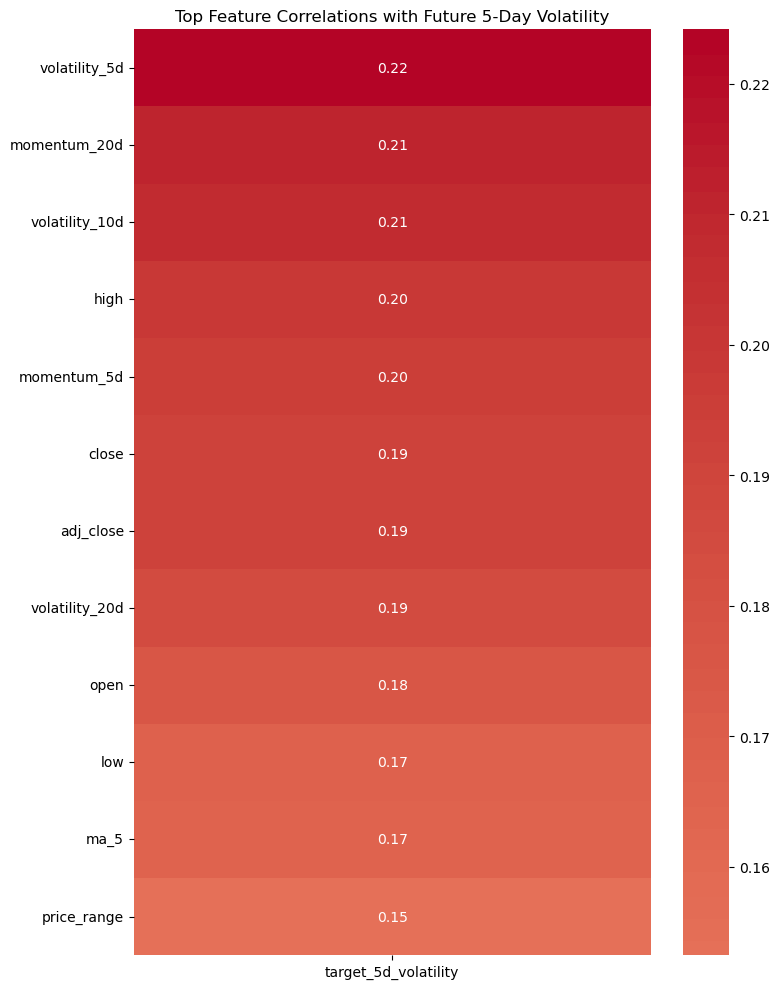

In [46]:
top_features = (
    strongest_features
    .head(12)
    .index
)

plt.figure(figsize=(8, 10))

sns.heatmap(
    correlation_matrix.loc[
        top_features,
        [target_column]
    ],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Top Feature Correlations with Future 5-Day Volatility"
)

plt.tight_layout()
plt.show()

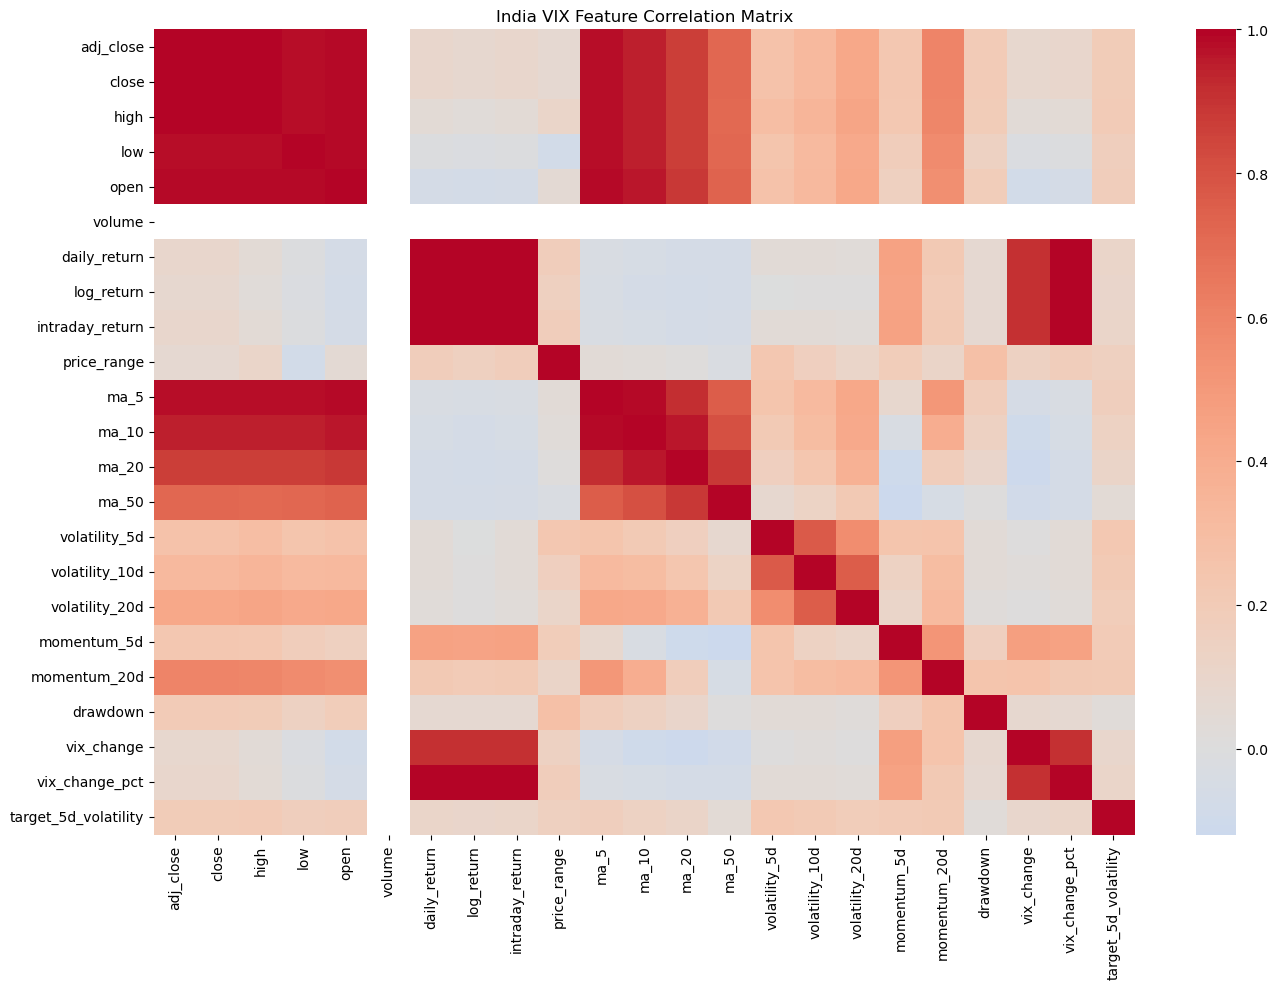

In [47]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("India VIX Feature Correlation Matrix")
plt.tight_layout()
plt.show()

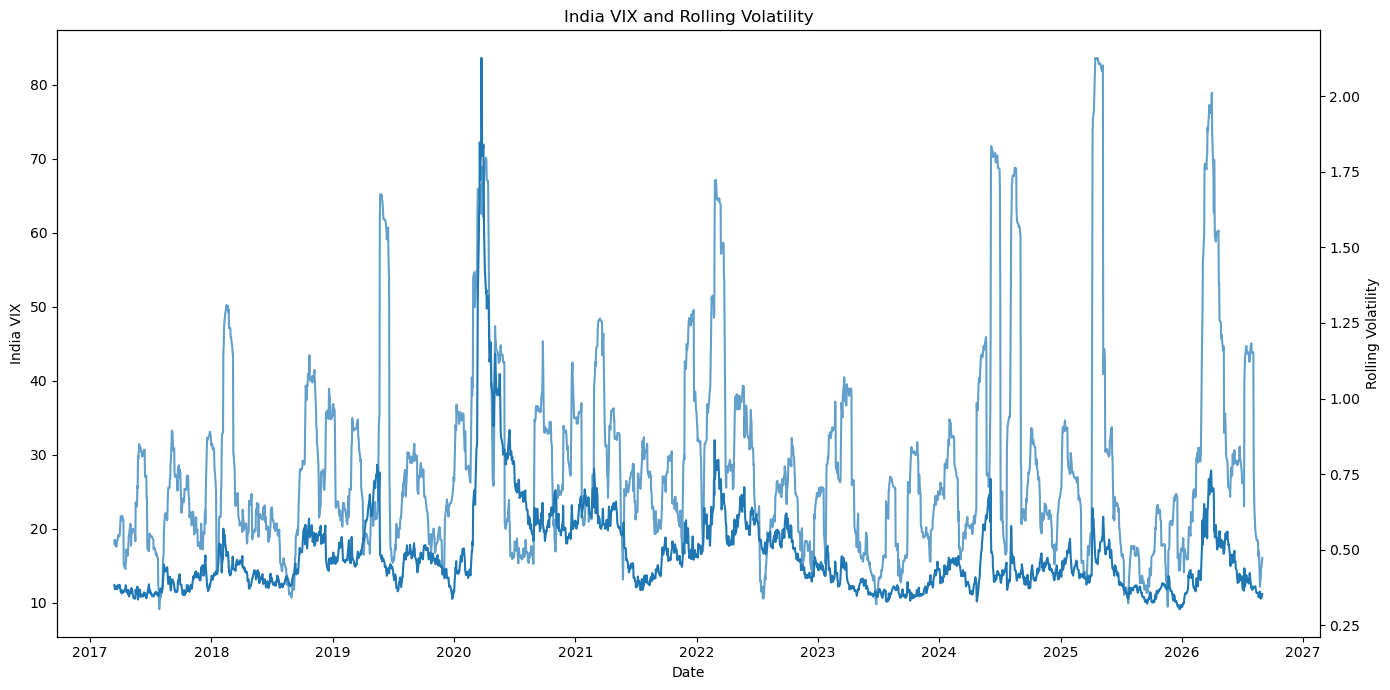

In [48]:
fig, ax1 = plt.subplots(
    figsize=(14, 7)
)

ax1.plot(
    df["date"],
    df[vix_column],
    label="India VIX"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("India VIX")

ax2 = ax1.twinx()

ax2.plot(
    df["date"],
    df[volatility_col],
    label="Rolling Volatility",
    alpha=0.7
)

ax2.set_ylabel("Rolling Volatility")

plt.title("India VIX and Rolling Volatility")
plt.tight_layout()
plt.show()

In [49]:
if "daily_return" in df.columns:

    largest_positive_returns = (
        df[
            ["date", "daily_return"]
        ]
        .dropna()
        .sort_values(
            "daily_return",
            ascending=False
        )
        .head(15)
    )

    largest_positive_returns

In [50]:
if "daily_return" in df.columns:

    largest_negative_returns = (
        df[
            ["date", "daily_return"]
        ]
        .dropna()
        .sort_values(
            "daily_return",
            ascending=True
        )
        .head(15)
    )

    largest_negative_returns

In [51]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 0


In [52]:
total_duplicates = df.duplicated().sum()

print("Total duplicate rows:", total_duplicates)

Total duplicate rows: 0


In [53]:
print("Invalid dates:", df["date"].isna().sum())

print(
    "Dates sorted:",
    df["date"].is_monotonic_increasing
)

Invalid dates: 0
Dates sorted: True


In [54]:
print("=" * 60)
print("INDIA VIX EDA SUMMARY")
print("=" * 60)

print("\nDataset:")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\nData Quality:")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nIndia VIX Statistics:")
print(df[vix_column].describe())

print("\nAverage Rolling Volatility:")
print(df[volatility_col].mean())

print("\nAverage Future 5-Day Volatility:")
print(df[target_column].mean())

print("\n90th Percentile VIX:")
print(high_vix_threshold)

print("\nEDA completed successfully.")

INDIA VIX EDA SUMMARY

Dataset:
Rows: 2319
Columns: 24
Start date: 2017-03-15 00:00:00
End date: 2026-08-31 00:00:00

Data Quality:
Missing values: 0
Duplicate rows: 0

India VIX Statistics:
count    2319.000000
mean       16.509888
std         6.611646
min         9.150000
25%        12.655000
50%        14.780000
75%        18.464999
max        83.610001
Name: close, dtype: float64

Average Rolling Volatility:
0.7741455041739282

Average Future 5-Day Volatility:
0.7168192834909101

90th Percentile VIX:
22.72399940490723

EDA completed successfully.


In [55]:
eda_summary = pd.DataFrame({
    "metric": [
        "number_of_rows",
        "number_of_columns",
        "start_date",
        "end_date",
        "average_vix",
        "median_vix",
        "maximum_vix",
        "minimum_vix",
        "average_rolling_volatility",
        "average_future_5d_volatility",
        "90th_percentile_vix"
    ],
    "value": [
        len(df),
        len(df.columns),
        str(df["date"].min()),
        str(df["date"].max()),
        df[vix_column].mean(),
        df[vix_column].median(),
        df[vix_column].max(),
        df[vix_column].min(),
        df[volatility_col].mean(),
        df[target_column].mean(),
        high_vix_threshold
    ]
})

eda_summary

,metric,value
0,number_of_rows,2319
1,number_of_columns,24
2,start_date,2017-03-15 00:00:00
3,end_date,2026-08-31 00:00:00
4,average_vix,16.509888
5,median_vix,14.78
6,maximum_vix,83.610001
7,minimum_vix,9.15
8,average_rolling_volatility,0.774146
9,average_future_5d_volatility,0.716819


In [56]:
summary_path = Path(
    "../data/processed/india_vix_eda_summary.csv"
)

eda_summary.to_csv(
    summary_path,
    index=False
)

print("EDA summary saved to:")
print(summary_path)

EDA summary saved to:
..\data\processed\india_vix_eda_summary.csv
